# Do Graph Neural Networks Improve Illicit Bitcoin Transaction Detection Under Temporal Distribution Shift?
## Evidence from the Elliptic Dataset

This notebook is the frozen publication-results viewer for Stages 1–4. Use the parameterized summary helper with a separate reproduction checkout for alternative outputs. **No training, checkpoint inference, robustness experiment or threshold optimization occurs here.** Execution reads the published aggregate tables and displays the saved figures in memory. The six Stage 5 figures are loaded from the release alongside the earlier figures.

**Main finding:** LightGBM leads pooled test AP on unperturbed benchmark inputs, but its 165-feature model detects only **4 of 169 known illicit transactions in steps 43–49 (2.37% recall)** at its frozen F1 threshold. Pooled ranking quality and late-period screening reliability are different questions. The late-window grouping is a **post-hoc descriptive diagnostic requested by the independent audit**, not a new selection rule.

The independent Stage 4 audit verified numerical and code consistency; it **did not independently reproduce inference from private checkpoints and predictions**. A November 15 local CPU replay verified all 33 frozen models using the original data and fitted artifacts. The maximum pooled AP difference was 0.00000221, with exact frozen F1 decisions. External independent reproduction remains unverified. The later manifest records the publication files and cannot establish the original complete code freeze.

Correct released-graph cutoffs cannot establish source-feature availability. Published successor aggregates may incorporate transactions after snapshot end. The conservative 18-feature sensitivity reduces exposure to known leakage mechanisms, with point-in-time safety still uncertified.

## 1. Research problem and motivation
Transaction screening is a rare-event ranking and decision problem. A useful model must identify illicit activity in later periods at a defensible operating point, not merely achieve high pooled AP. We compare Logistic Regression, LightGBM, GraphSAGE, GAT, and GraphSAGE + Historical GRU Context using matching 18-, 93- and 165-feature configurations.

The original release is a historical benchmark. Known labels are selected, features have unresolved source-level leakage, and no group is certified leakage-free. Neither causal benefits nor live deployment performance can be established here.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from io import BytesIO
from PIL import Image as PreviewImage

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "results/stage4/full_run/model_comparison.csv").is_file():
    raise FileNotFoundError("Open the completed public repository from its root or notebooks/.")
GROUPS = ["conservative18", "local93", "published165"]
ARCHITECTURES = ["logistic_regression", "lightgbm", "graphsage", "gat", "sage_gru"]
shown_figures = []

def load_table(relative_path):
    return pd.read_csv(ROOT / "results" / relative_path)

def show_saved(name):
    path = ROOT / "reports/figures" / f"{name}.png"
    if not path.is_file():
        raise FileNotFoundError(f"Required saved figure missing: {name}")
    with PreviewImage.open(path) as preview:
        preview.thumbnail((1150, 900))
        buffer = BytesIO()
        preview.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))
    shown_figures.append(name)

comparison = load_table("stage4/full_run/model_comparison.csv")
metrics = load_table("stage4/full_run/final_test_metrics.csv")
periods = load_table("stage4/full_run/per_time_step_metrics.csv")
windows = load_table("stage5/operating_window_metrics.csv")
curves = load_table("stage5/curve_display_points.csv")
curve_bins = load_table("stage5/calibration_display_bins.csv")
intervals = load_table("stage4/full_run/paired_bootstrap_intervals.csv")
robustness = load_table("stage4/full_run/robustness_summary.csv")
protocol = json.loads((ROOT / "results/stage4/frozen_protocol.json").read_text())
assert len(comparison) == 15 and len(metrics) == 66
assert metrics.n_labeled.eq(16670).all() and metrics.n_illicit.eq(1083).all()
assert len(curves) == 3030 and len(curve_bins) == 300

## 2. Dataset and experimental design
The **original Elliptic dataset** contains 203,769 transactions, 234,355 directed edges, 49 snapshots and 166 published features including time. Labels: illicit 4,545; licit 42,019; unknown 157,205. Unknown nodes remain eligible graph context but are excluded from losses and evaluation.

| Role | Steps | Permitted use |
|---|---|---|
| Training | 1–29 | Fit estimators and preprocessing |
| Model selection | 30–31 | Hyperparameters, weighting and stopping |
| Calibration | 32–33 | Saved Platt maps and operating rules |
| Later validation | 34 | Assessment without retuning |
| Final test | 35–49 | Frozen evaluation; no new selection |

18 features are a narrower transaction sensitivity; 93 include address-history variables; 165 also include published neighborhood aggregates. **None is certified leakage-free**, and all-feature LightGBM is not a graph-free information baseline. Source-level feature availability is not established by chronological row masking.

,partition,licit,illicit,unknown,transactions,known_labels,illicit_prevalence_known,label_coverage
0,train,23510,2871,94423,120804,26381,0.108828,0.218379
1,validation,2922,591,11948,15461,3513,0.168232,0.227217
2,test,15587,1083,50834,67504,16670,0.064967,0.246948


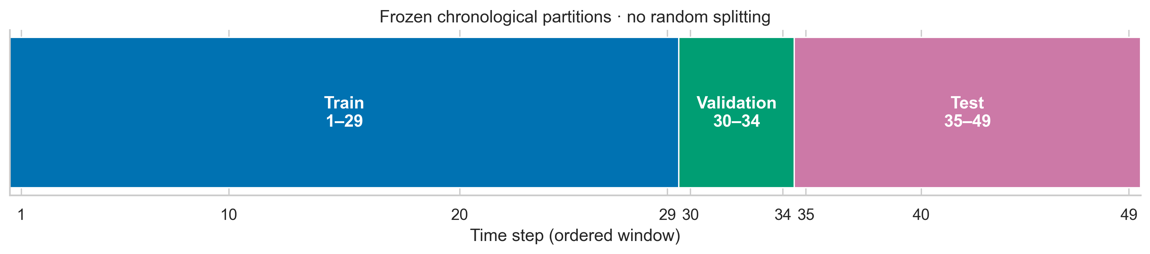

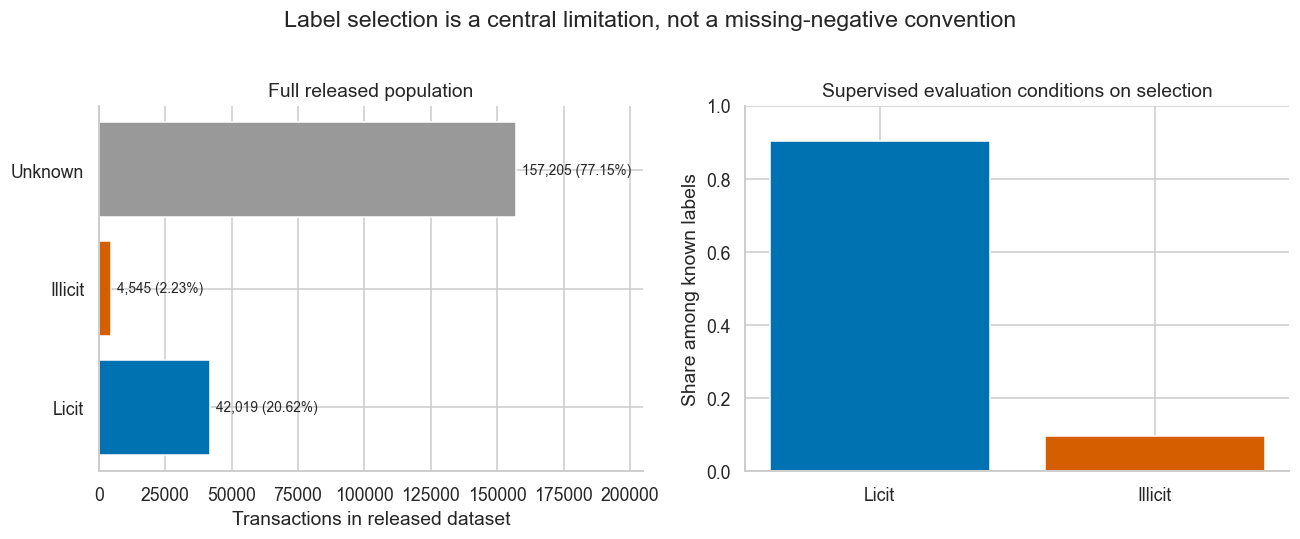

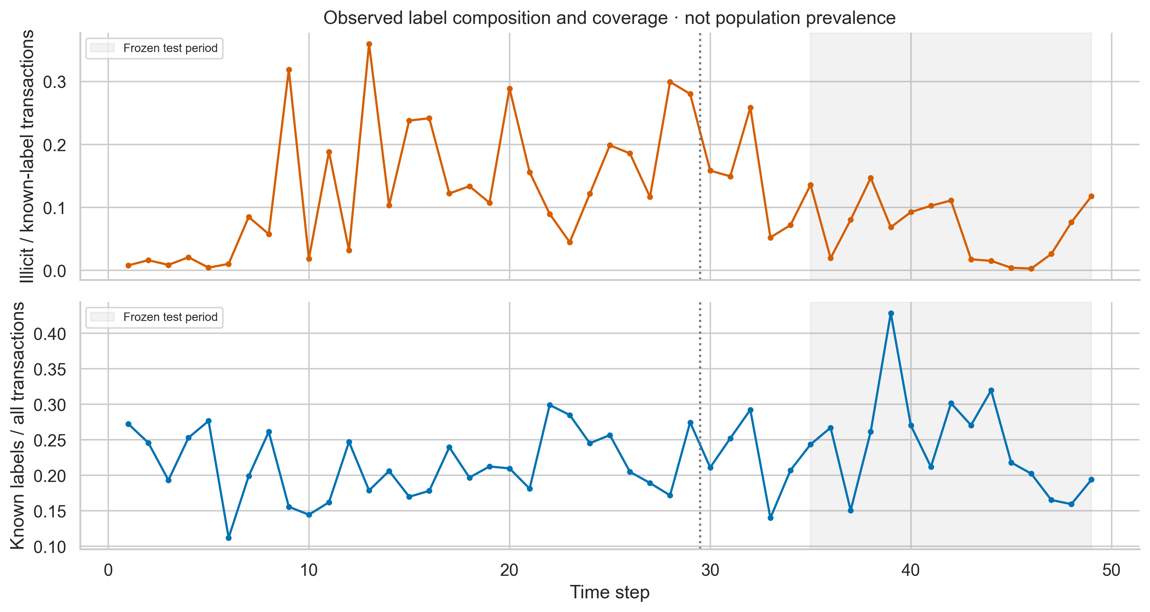

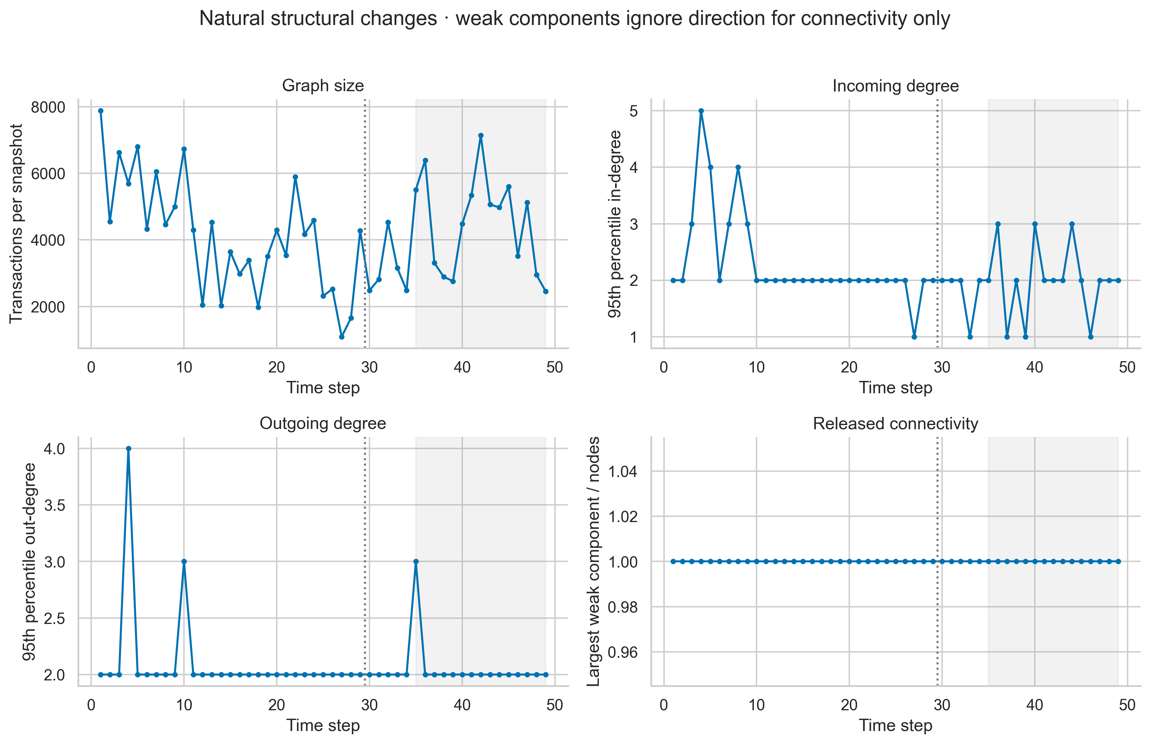

In [2]:
display(load_table("split_summary.csv"))
show_saved("14_chronological_partitions")
validation = json.loads((ROOT / "results/data_validation.json").read_text())
counts = np.array([42019, 4545, 157205])
labels = ["Licit", "Illicit", "Unknown"]
# The saved Stage 1 report is the source of these verified release counts.
assert validation["licit"] == counts[0] and validation["illicit"] == counts[1] and validation["unknown"] == counts[2]
show_saved("stage5_01_label_population")
show_saved("stage4_04_prevalence_coverage")
show_saved("stage4_06_graph_shift")

The gray unknown group is 77.15% of the release. Selected-label illicit prevalence changes over time and cannot estimate illicit prevalence among all transactions. Every released snapshot is one weak component; changing graph size and degree tails still alter local aggregation. The 49 snapshots are ordered benchmark periods, not a basis for assigning an unverified external event or causal regime.

## 3. Traditional ML benchmarks
Both tabular models use their saved training-only preprocessing, 30–31-selected settings and seed 42. LightGBM improves substantially over logistic regression on this benchmark. Its published-feature gain does not quantify how much comes from legitimate signal versus source-level contamination.

**Ranking vs screening:** pooled AP integrates score rankings across all test snapshots. Recall at a saved threshold measures detections at a particular operating point. Calibration, class balance and cross-period score changes affect threshold transfer. They are not interchangeable success criteria.

architecture,logistic_regression,lightgbm,graphsage,gat,sage_gru
feature_configuration,,,,,
conservative18,0.0922,0.5993,0.4263 ± 0.0194,0.2059 ± 0.0699,0.4466 ± 0.0101
local93,0.1956,0.7639,0.6246 ± 0.0254,0.5000 ± 0.0618,0.6211 ± 0.0082
published165,0.2664,0.7866,0.3953 ± 0.0463,0.4387 ± 0.0507,0.4599 ± 0.0069


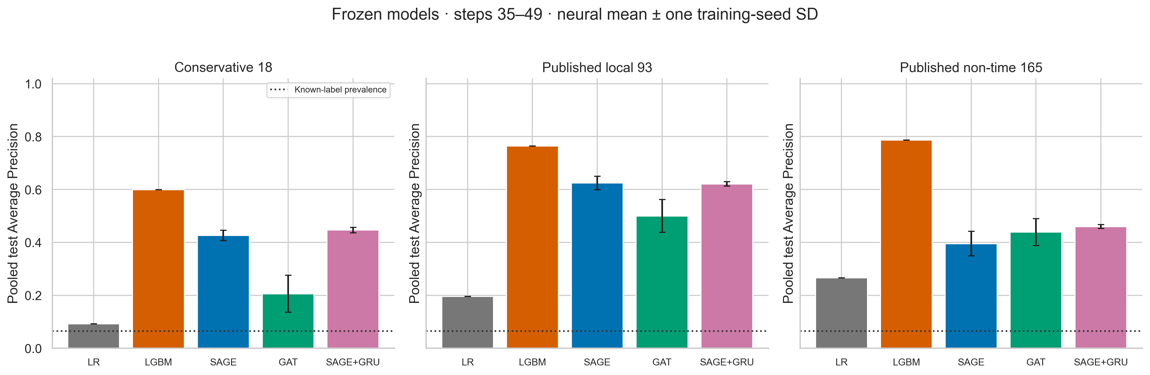

,window,first_step,last_step,tp,fn,illicit_labels,recall,false_positive_rate
60,early_test,35,42,780,134,914,0.8534,0.0085
61,late_test,43,49,4,165,169,0.0237,0.0100
62,pooled_test,35,49,784,299,1083,0.7239,0.0091


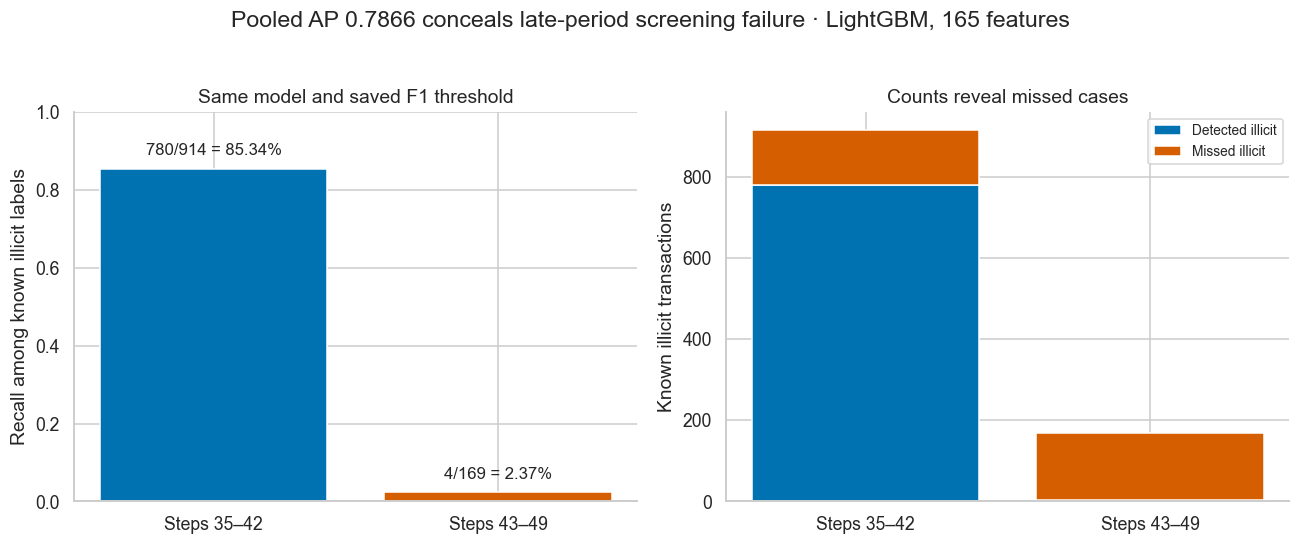

In [3]:
headline = comparison.copy()
headline["AP (mean ± seed SD)"] = [f"{r.ap_mean:.4f}" + (f" ± {r.ap_seed_sd:.4f}" if r.seeds > 1 else "") for r in headline.itertuples()]
display(headline.pivot(index="feature_configuration", columns="architecture", values="AP (mean ± seed SD)").reindex(GROUPS)[ARCHITECTURES])
show_saved("stage4_01_final_test_ap")
focus = windows.loc[windows.architecture.eq("lightgbm") & windows.feature_configuration.eq("published165")].copy()
late = focus.loc[focus.window.eq("late_test")].iloc[0]
assert late.tp == 4 and late.illicit_labels == 169
assert np.isclose(late.recall, 4/169)
display(focus[["window","first_step","last_step","tp","fn","illicit_labels","recall","false_positive_rate"]].round(4))
show_saved("stage5_02_late_operating_failure")

The 165-feature LightGBM detects **780/914 early-test positives (85.34%)**, but only **4/169 late-test positives (2.37%)**. The diagnostic includes step 46's two positives through confusion counts even though that step's separately reported AP/recall is unavailable under the five-positive reporting rule. No threshold was optimized on these test outcomes. This is a failure of the frozen benchmark operating policy; it does not measure a production system.

## 4. Graph neural network performance
GraphSAGE and GAT use separate directed graphs for each snapshot, retaining unknown nodes as label-free context. Published sender-to-receiver direction is preserved. Three completed training seeds are reported individually and as mean/SD; these seeds do not create independent test populations.

The next curves use saved seed-42 predictions on identical known-label test nodes. The public files store a **101-point interpolated display grid**, not transaction records. AP and ROC-AUC annotations come from full saved metrics, not integration over this grid.

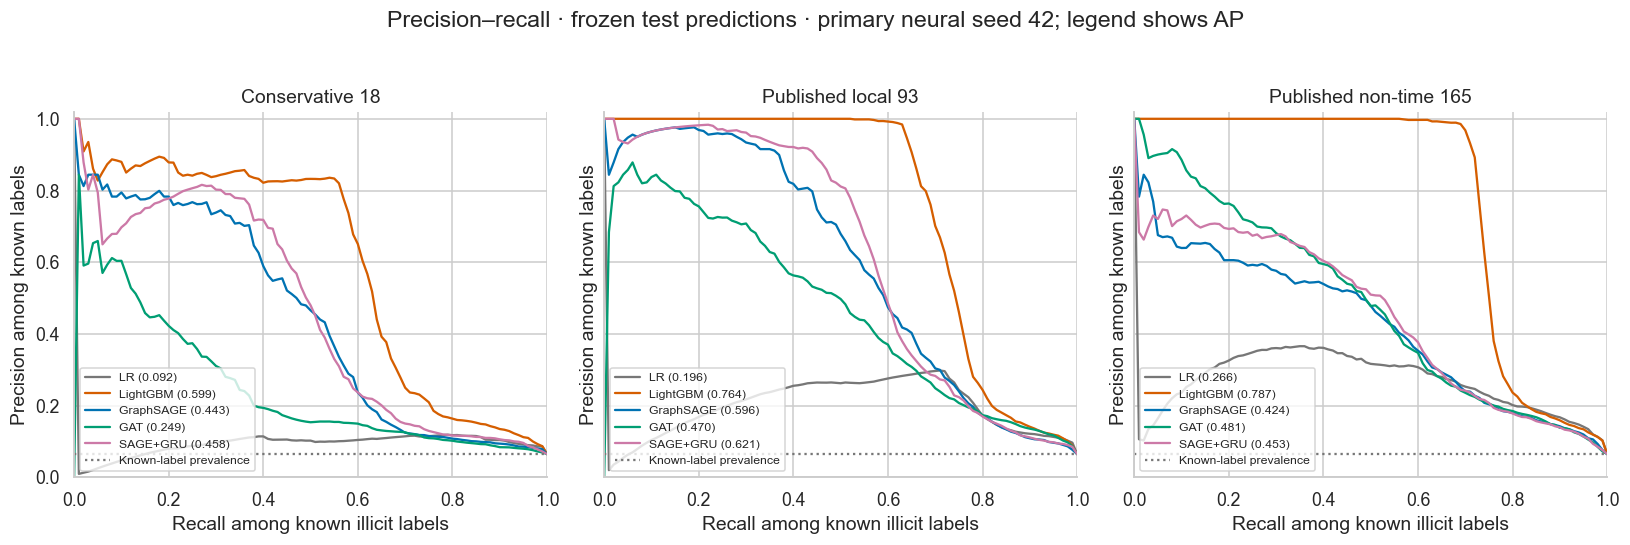

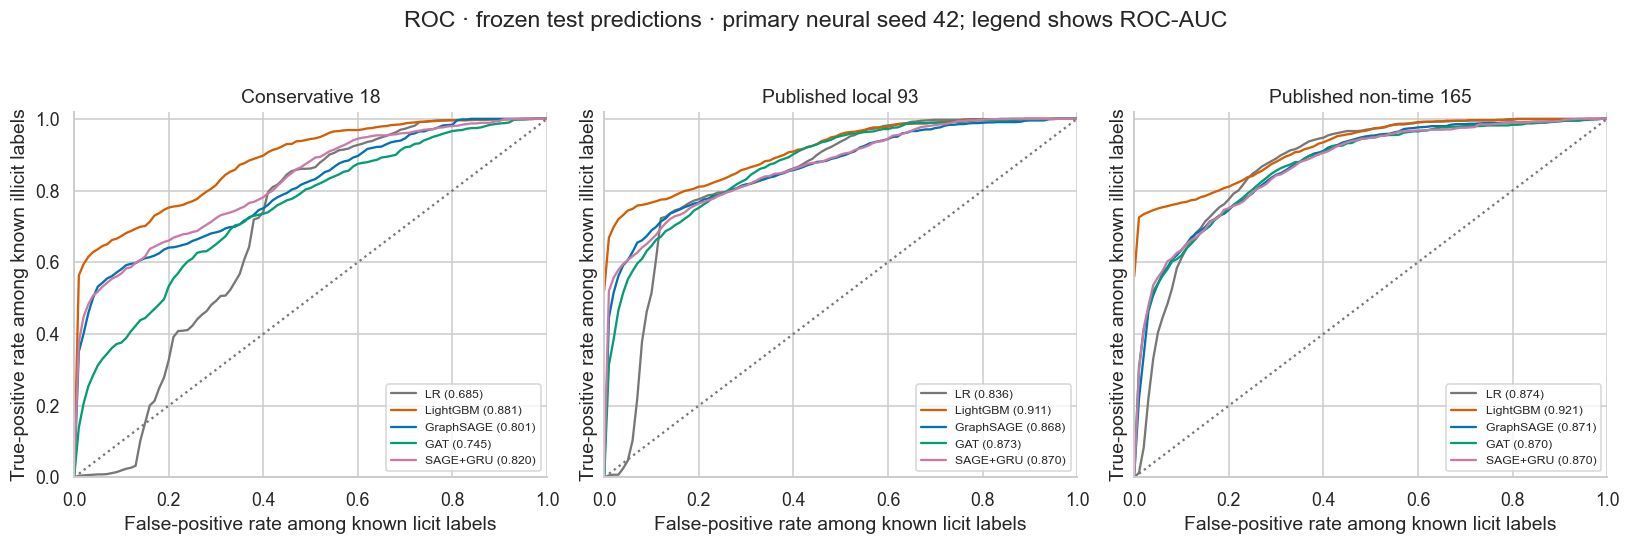

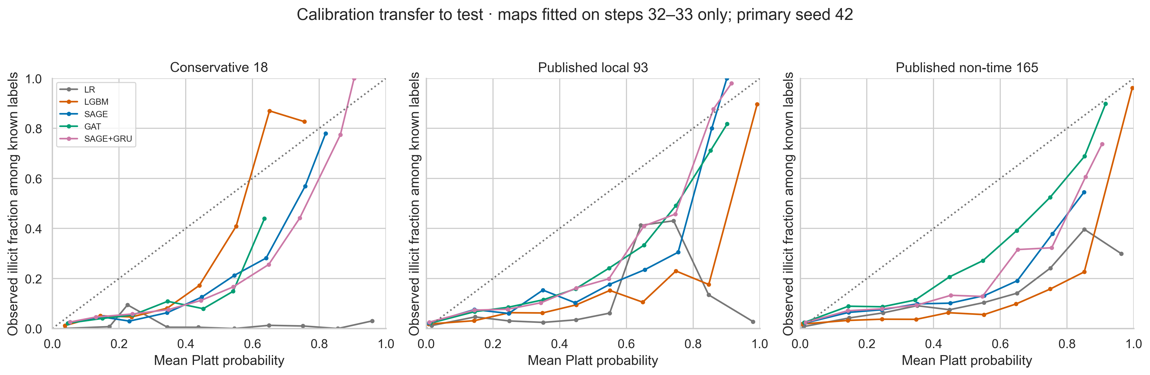

In [4]:
show_saved("stage5_03_final_precision_recall")
show_saved("stage5_04_final_roc")
show_saved("stage4_15_calibration_transfer")

LightGBM leads pooled AP on unperturbed benchmark inputs for each matched feature group; this does not guarantee late-period recall. ROC-AUC can appear reasonable despite poor rare-event precision. Saved Platt calibration improves neural mean Brier in all nine settings, but transfer is mixed for tabular models. No calibrated variant was selected for better test performance.

## 5. Temporal learning results
GraphSAGE + Historical GRU Context encodes each snapshot, averages all observed node embeddings and updates a GRU **after** current predictions. Context at $t$ contains only strictly earlier summaries. Transactions are not persistent identities, and no cross-time edges are invented.

The existing linear head is $\ell_{it}=w_z^T z_{it}+w_h^T h_{t-1}+b$. Historical context is a **common snapshot logit offset**. It can change probability levels and pooled cross-snapshot ranking but cannot directly rerank nodes within a snapshot at fixed weights. Separately fitted encoders also differ.

,feature_configuration,observed_ap_difference,ci_low,ci_high
3,conservative18,0.0203,-0.0072,0.0400
7,local93,-0.0035,-0.0110,0.0067
11,published165,0.0647,0.0385,0.0832


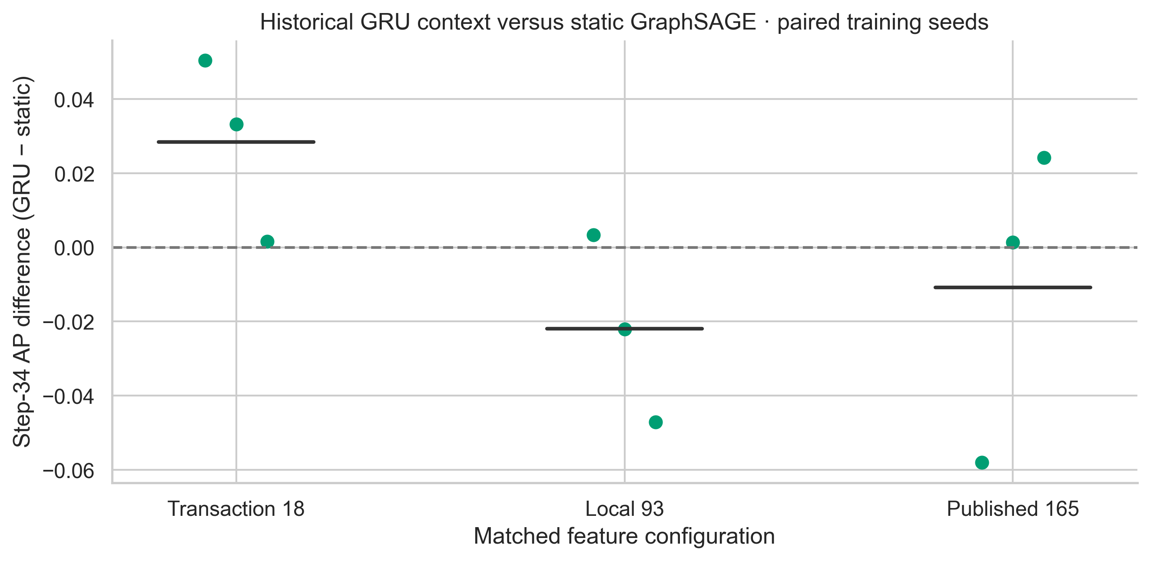

In [5]:
temporal = intervals.loc[intervals.first_architecture.eq("sage_gru") & intervals.second_architecture.eq("graphsage")]
display(temporal[["feature_configuration","observed_ap_difference","ci_low","ci_high"]].round(4))
show_saved("stage3_08_temporal_difference")

The reused plot is explicitly **later-validation step 34**, not a final-test ablation. Final pooled GRU-minus-static AP is +0.0203 / −0.0035 / +0.0647. The first two descriptive block intervals include zero. The 165-feature difference is positive under this resampling scheme, but cannot isolate a causal historical effect. A controlled nonlinear-head experiment was not performed.

## 6. Distribution shift
The reference feature window is all observed nodes in steps 1–29. Training-quantile PSI, KS distance and normalized Wasserstein measures are saved for all 165 columns. KS is a descriptive distance; dependent transactions invalidate naive IID p-values. Selected-label prevalence and label coverage are reported separately.

Feature shifts do not prove concept drift. Changes in class composition, label acquisition, conditional relationships and graph sampling can coexist; this release cannot cleanly separate them.

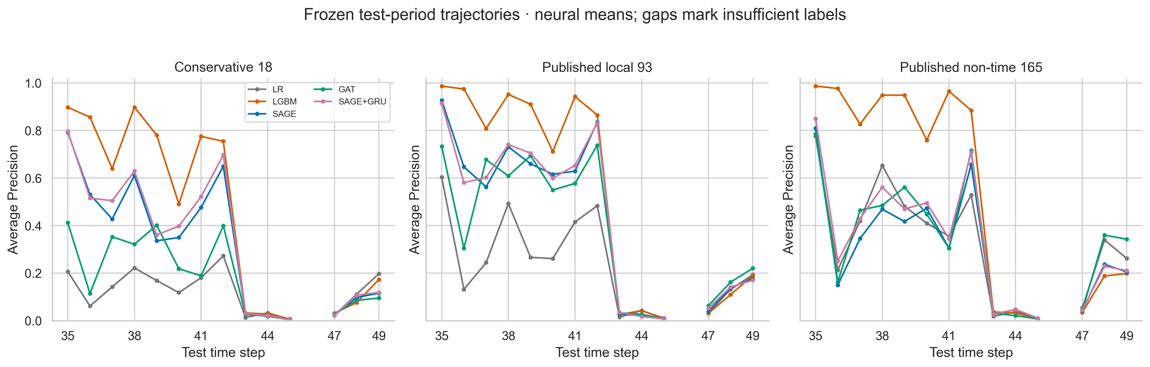

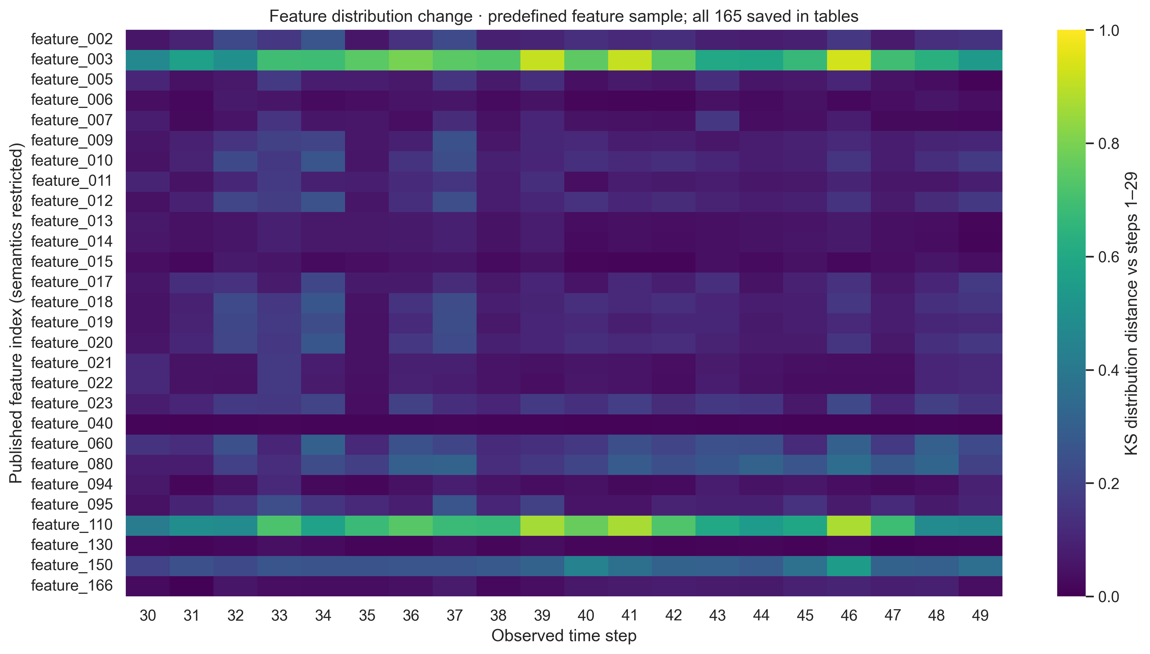

,time_step,n_illicit,prevalence,average_precision,recall,ranking_metric_available
0,35,182,0.1357,0.9867,0.9560,True
1,36,33,0.0193,0.9765,0.9697,True
2,37,40,0.0803,0.8270,0.6000,True
3,38,111,0.1468,0.9489,0.8919,True
4,39,81,0.0685,0.9484,0.9259,True
5,40,112,0.0925,0.7595,0.6607,True
6,41,116,0.1025,0.9653,0.9483,True
7,42,239,0.1110,0.8847,0.8033,True
8,43,24,0.0175,0.0368,0.0000,True
9,44,24,0.0151,0.0318,0.0417,True


In [6]:
show_saved("stage4_02_ap_over_time")
show_saved("stage4_05_feature_shift")
step_metrics = periods.loc[periods.architecture.eq("lightgbm") & periods.feature_configuration.eq("published165") & periods.calibration.eq("raw")]
display(step_metrics[["time_step","n_illicit","prevalence","average_precision","recall","ranking_metric_available"]].round(4))

All families deteriorate around steps 43–47. Some neural means exceed LightGBM in individual late snapshots, but the evidence does not establish persistent out-of-time superiority or attribute the break to a real-world event. Step 46 has two illicit labels and missing per-step ranking/recall metrics; step 45 has five positives and remains unstable.

## 7. Robustness experiments
These are **inference-time sensitivities of saved weights**, not new deployment simulations. Noise adds a training-derived SD multiple of Gaussian values; masking replaces entries by known-training means. Edge removal and partial rewiring preserve snapshot boundaries and direction semantics; rewiring preserves total directed count, not degrees. Frozen thresholds remain unchanged.

The GRU's 1–34 prefix stays unperturbed, while corrupted test summaries propagate after each test prediction. Published precomputed neighborhood features remain unchanged under adjacency edits, creating a potential inconsistency. Equal percentages across corruption types are not equal severity.

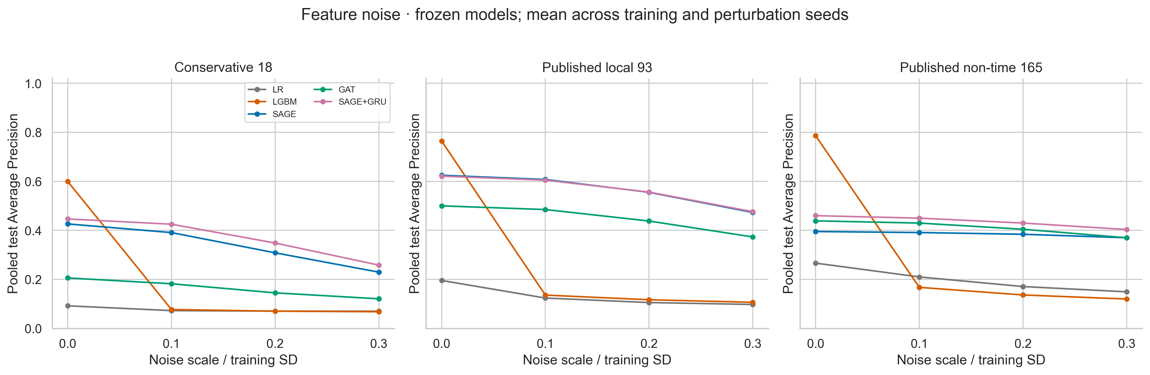

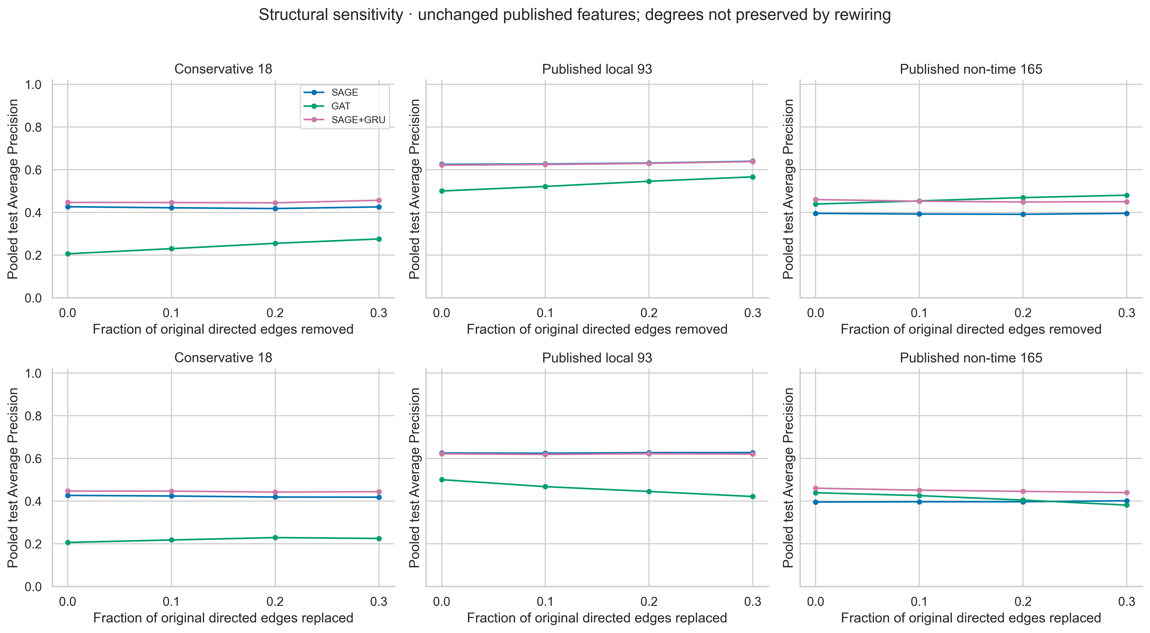

,architecture,feature_configuration,perturbation,ap_mean,delta_ap_mean
2,gat,conservative18,mask,0.1572,-0.0487
5,gat,conservative18,noise,0.1208,-0.0851
8,gat,conservative18,remove,0.2753,0.0694
11,gat,conservative18,rewire,0.2245,0.0186
14,gat,local93,mask,0.3640,-0.1360
17,gat,local93,noise,0.3731,-0.1268
20,gat,local93,remove,0.5663,0.0663
23,gat,local93,rewire,0.4210,-0.0790
26,gat,published165,mask,0.3400,-0.0987
29,gat,published165,noise,0.3698,-0.0689


In [7]:
show_saved("stage4_08_feature_noise")
show_saved("stage4_10_edge_robustness")
display(robustness.loc[robustness.severity.eq(.3),["architecture","feature_configuration","perturbation","ap_mean","delta_ap_mean"]].round(4))

At 0.30 training-SD Gaussian noise, historical-GRU AP is 0.2582 / 0.4761 / 0.4033 versus LightGBM 0.0681 / 0.1065 / 0.1199. Unbounded continuous noise may violate realistic feature support. With 30% entry masking, LightGBM remains strongest. Thirty-percent edge removal increases GAT AP in every setting; useful graph information is not established merely because a message-passing model uses the released graph.

## 8. Statistical comparisons
Seed SD describes variability from three completed neural training runs. It is **not** a test-population confidence interval. The separate paired bootstrap resamples 15 test snapshots in circular blocks of length three, five blocks per replicate, with 1,000 fixed-seed replicates. Pooled AP is recomputed with snapshot multiplicity weights, then averaged across the fixed neural seeds.

These are conditional intervals for saved predictions along their realized histories, not GRU forecasts recomputed under hypothetical reordered histories. Limited temporal coverage, stationarity/dependence assumptions, endpoint wrap and 12 unadjusted pointwise comparisons constrain inference.

,feature_configuration,first_architecture,second_architecture,observed_ap_difference,ci_low,ci_high,valid_replications
0,conservative18,lightgbm,graphsage,0.1731,0.0785,0.2501,1000
1,conservative18,lightgbm,gat,0.3934,0.1950,0.4695,1000
2,conservative18,lightgbm,sage_gru,0.1528,0.0535,0.2390,1000
3,conservative18,sage_gru,graphsage,0.0203,-0.0072,0.0400,1000
4,local93,lightgbm,graphsage,0.1393,0.0647,0.2181,1000
5,local93,lightgbm,gat,0.2640,0.1838,0.3417,1000
6,local93,lightgbm,sage_gru,0.1428,0.0700,0.2215,1000
7,local93,sage_gru,graphsage,-0.0035,-0.0110,0.0067,1000
8,published165,lightgbm,graphsage,0.3913,0.2354,0.4900,1000
9,published165,lightgbm,gat,0.3478,0.1934,0.4424,1000


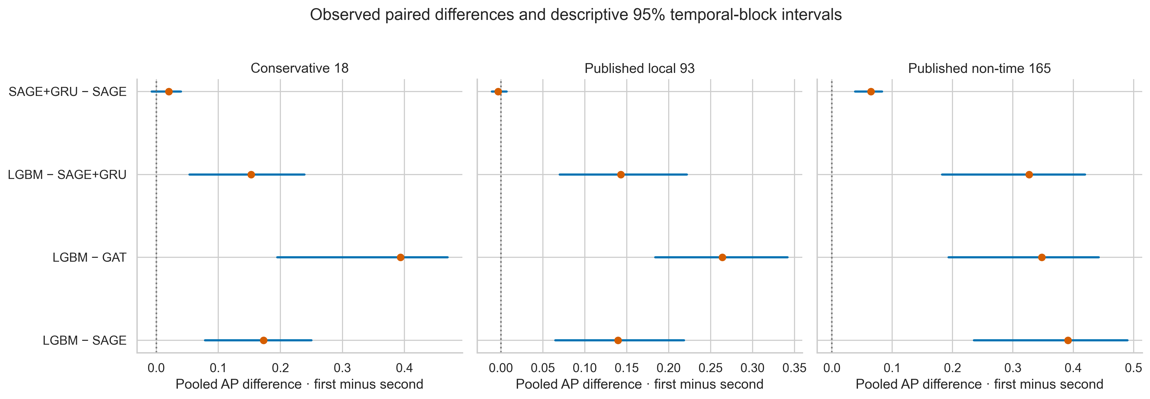

In [8]:
display(intervals[["feature_configuration","first_architecture","second_architecture","observed_ap_difference","ci_low","ci_high","valid_replications"]].round(4))
show_saved("stage4_11_paired_uncertainty")

All nine LightGBM-minus-neural descriptive intervals lie above zero. This supports stability of the observed pooled gap under the specified resampling scheme, not definitive significance or generalization beyond this release. Statistical comparisons of pooled ranking do not negate the late-period frozen-threshold failure.

## 9. Ablation studies, errors and computational cost
Stage 3's **retrained development controls** compare original edges, self-only inputs, one within-snapshot rewiring draw and selected reverse-direction sensitivities at seed 42. These controls are not final-test-selected alternatives. Stage 4 edge perturbations instead modify adjacency at inference with fixed weights; the two designs answer different questions.

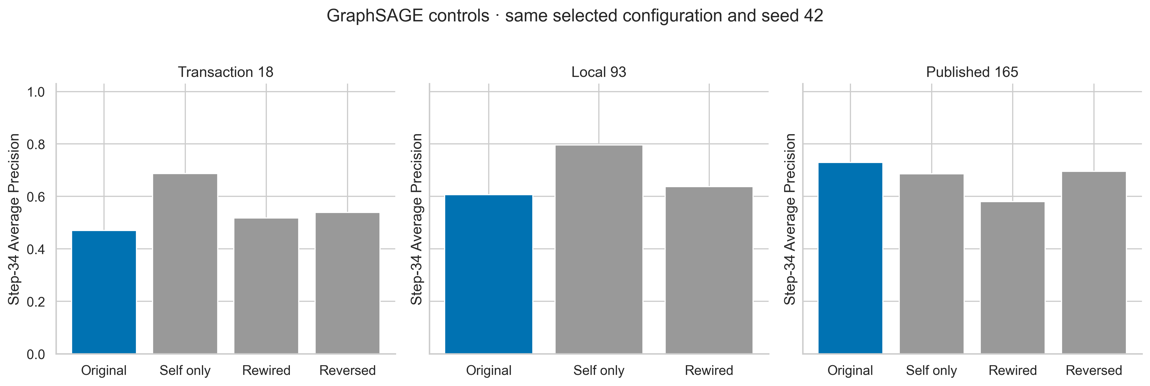

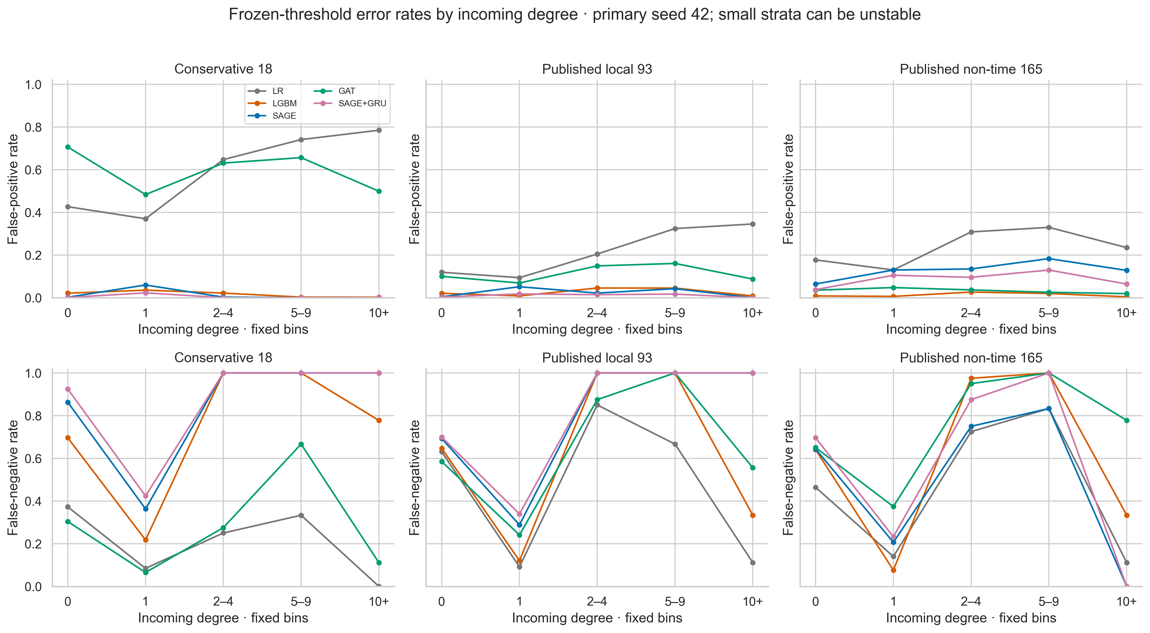

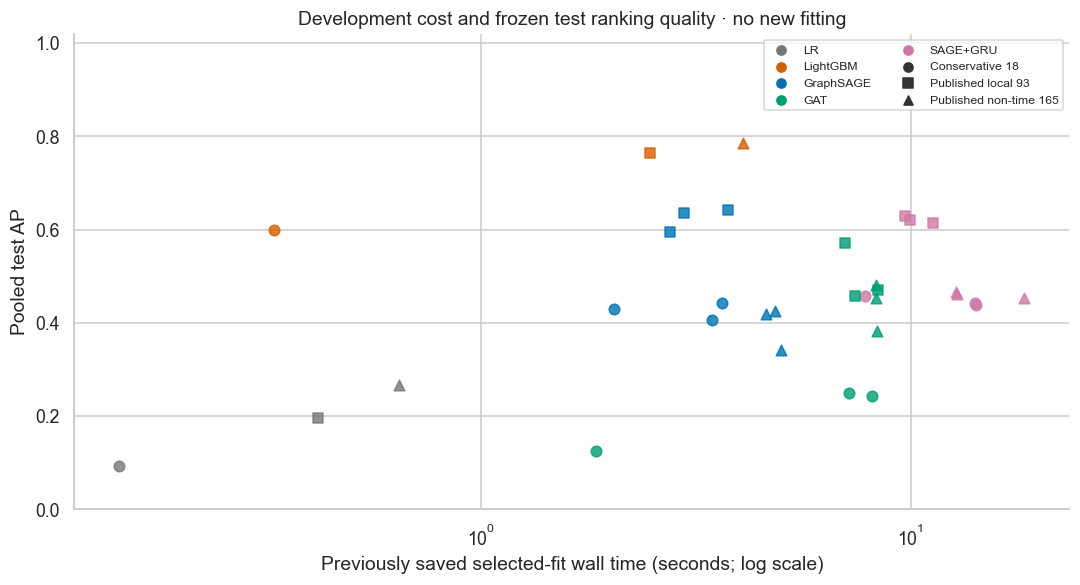

In [9]:
show_saved("stage3_07_graph_controls")
show_saved("stage4_13_error_by_degree")
show_saved("stage5_05_training_cost")

Self-only controls outperform original-edge GraphSAGE for 18/93 features in the single-seed later-validation comparison. Degree-conditioned errors and threshold disagreements are exploratory diagnostics, not selection evidence. Sparse strata can produce extreme error rates.

Fit times use mixed validated CPU/MPS hardware and include neural stopping validation; they are not controlled speed benchmarks. Nineteen of 44 fitted runs, including nine selected main models, reached the update cap. Graph complexity did not improve AP on unperturbed benchmark inputs, but limited optimization prevents a universal architecture conclusion.

## 10. Conclusions and limitations
The project separates **reproducible benchmark observations**, **conservative feature sensitivities**, and claims the released data cannot establish. Šafář et al. (2026) identify feature opacity and contamination problems; chronology and a training-only scaler do not certify source validity. Known-label selection, shared entities, incomplete neighborhoods and limited time coverage remain unresolved.

Publication fixes preserve the original frozen JSON, add a dated release manifest, validate complete caches and edge audits, recover aggregate tables from committed scenarios, and explicitly skip absent private artifacts in public tests. A later manifest cannot prove which unrecorded notebook code originally executed. The external audit's numerical/code checks are narrower than independent private-artifact inference reproduction.

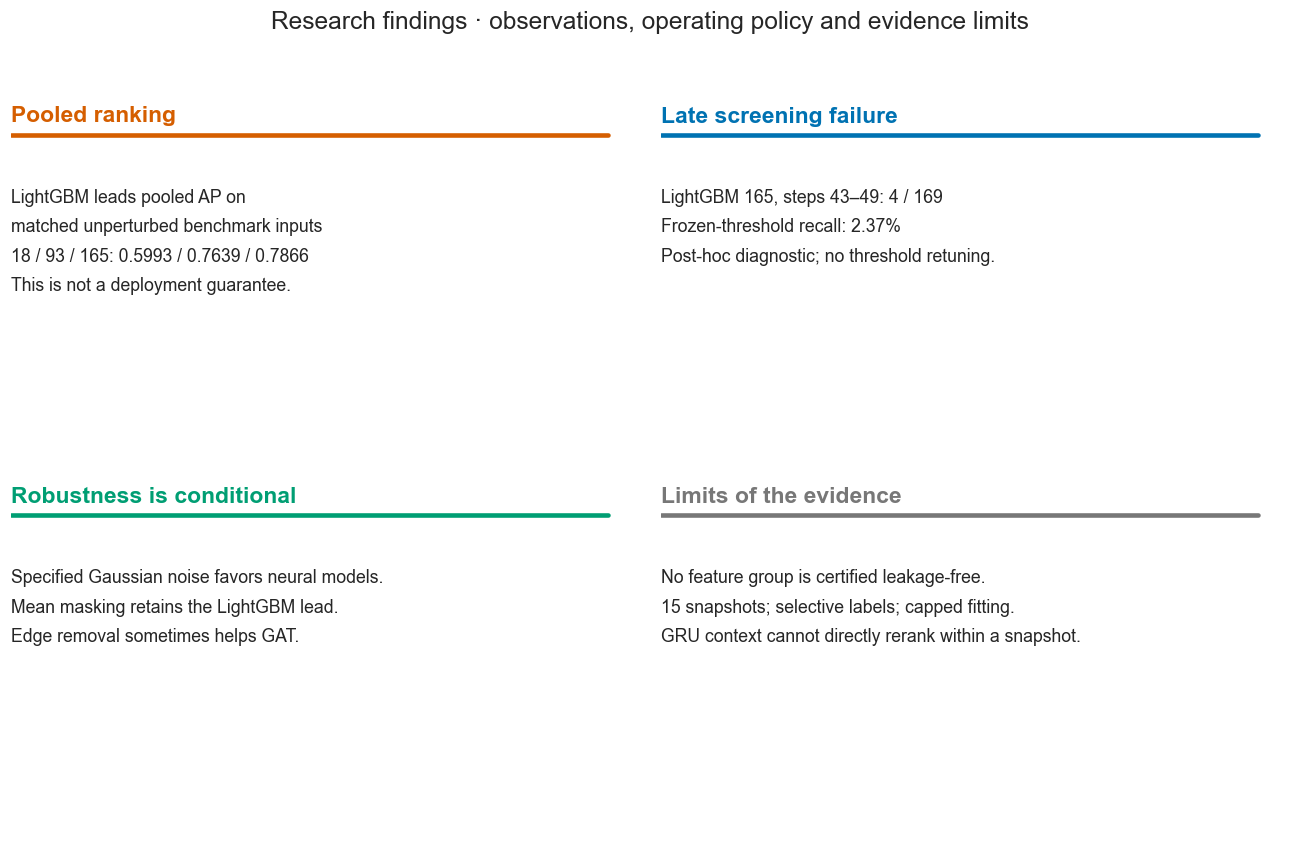

**Frozen publication results.** Displayed all 19 saved figures and their published tables.

In [10]:
show_saved("stage5_06_findings_summary")
historical_summary = json.loads((ROOT / "results/stage5/execution_summary.json").read_text())
assert shown_figures == historical_summary["figures_shown"]
display(Markdown("**Frozen publication results.** Displayed all 19 saved figures and their published tables."))

### References and evidence
- Weber et al. (2019), [Elliptic benchmark study](https://arxiv.org/abs/1908.02591); [original dataset](https://www.kaggle.com/datasets/ellipticco/elliptic-data-set).
- Hamilton et al. (2017), [GraphSAGE](https://arxiv.org/abs/1706.02216); Veličković et al. (2018), [GAT](https://arxiv.org/abs/1710.10903).
- Šafář et al. (2026), [feature opacity and leakage](https://doi.org/10.1016/j.fsidi.2026.302124); [public feature-semantics documentation](https://github.com/nesfit/DeanonymizedEllipticBitcoinDataset).
- Editable [research paper](../reports/research_paper.md), [quality report](../reports/final_quality_report.md) and [reproducibility guide](../reports/reproducibility.md). The dated release manifest is written after final packaging checks; it records this release and cannot retroactively establish the original complete code freeze.